# **Sentiment Analysis**

# **Environment Setup & Library Imports**

In [34]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, confusion_matrix, roc_auc_score
from transformers import pipeline
import torch

# **Dataset Retrieval**
Downloading the US Airline Sentiment dataset from Kaggle.

In [35]:
import kagglehub

# Download dataset
path = kagglehub.dataset_download("tango911/airline-sentiment-tweets")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'airline-sentiment-tweets' dataset.
Path to dataset files: /kaggle/input/airline-sentiment-tweets


# **Data Preparation**
Preparing the downloaded file as Tweets.csv.

In [36]:
import os
import shutil

files = os.listdir(path)
csv_files = [f for f in files if f.lower().endswith('.csv')]
if csv_files:
    src_file = os.path.join(path, csv_files[0])
    shutil.copy(src_file, 'Tweets.csv')
    print(f"Copied {csv_files[0]} to Tweets.csv!")
else:
    print("No CSV file found.")

Copied train.csv to Tweets.csv!


# **Load Hugging Face Pipeline**


In [45]:
classifier = pipeline('sentiment-analysis')
print(type(classifier))

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

<class 'transformers.pipelines.text_classification.TextClassificationPipeline'>


# **Basic Tests**

Testing to see if the model can categorize sentences into positive or negative sentiments accurately.

In [68]:
classifier([
    "This was a great book", #positive sentiment
    "I did not understood any of it"#negative sentment
])

[{'label': 'POSITIVE', 'score': 0.9998410940170288},
 {'label': 'NEGATIVE', 'score': 0.9996486902236938}]

In [67]:
classifier([
    "akbjeiuhhc",#gibberish
    "oirtnreion",#giberish
])

[{'label': 'NEGATIVE', 'score': 0.9662609696388245},
 {'label': 'POSITIVE', 'score': 0.7660978436470032}]

### **Observation:** Random Gibberish may produce positive or negative score.

## **Testing Trippy Linguistic Nuances**
Evaluating slang, idiomatic expressions, and subtle article based
semantic flips on our sentiment analyzer.

In [50]:
trippy_sentences = [
    "This is shit", #negative
    "This is the shit", #positive slang
    "That is bad", #negative
    "That is bad ass" #positive in slang
]

classifier(trippy_sentences)

[{'label': 'NEGATIVE', 'score': 0.9996411800384521},
 {'label': 'NEGATIVE', 'score': 0.9993982315063477},
 {'label': 'NEGATIVE', 'score': 0.9997939467430115},
 {'label': 'NEGATIVE', 'score': 0.9997881054878235}]

### **Observation:** Clearly the model struggles with slang and article based semantic flip.

In [69]:
classifier([
    "This is the best shit",#addition of "best"
    "Good",
    "terrific",
    "bad",
    "garbage"
])


[{'label': 'POSITIVE', 'score': 0.9996953010559082},
 {'label': 'POSITIVE', 'score': 0.9998161196708679},
 {'label': 'POSITIVE', 'score': 0.9998639822006226},
 {'label': 'NEGATIVE', 'score': 0.999782383441925},
 {'label': 'NEGATIVE', 'score': 0.9998012185096741}]

### **Observation:** Addition of positive superlative adjectives clearly produces positive scores and vice versa.

# **Load Dataset**
Loading the airline tweets sentiment dataset containing Twitter posts about major US airlines with categorized emotions (positive, negative, or neutral) along with metadata like confidence scores, negative reasons, and user locations.

In [39]:
df = pd.read_csv("Tweets.csv")
df.head(5)

,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,name,retweet_count,text,tweet_created,tweet_location,user_timezone
0,Tr_tweet_1,neutral,1.0000,NaN,NaN,Virgin America,cairdin,0.0,@VirginAmerica What @dhepburn said.,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,Tr_tweet_2,positive,0.3486,NaN,0.0000,Virgin America,jnardino,0.0,@VirginAmerica plus you've added commercials t...,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,Tr_tweet_3,neutral,0.6837,NaN,NaN,Virgin America,yvonnalynn,0.0,@VirginAmerica I didn't today... Must mean I n...,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,Tr_tweet_4,negative,1.0000,Bad Flight,0.7033,Virgin America,jnardino,0.0,@VirginAmerica it's really aggressive to blast...,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,Tr_tweet_5,negative,1.0000,Can't Tell,1.0000,Virgin America,jnardino,0.0,@VirginAmerica and it's a really big bad thing...,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)


# **Exploratory Data Analysis**


Visualizing the dataset.

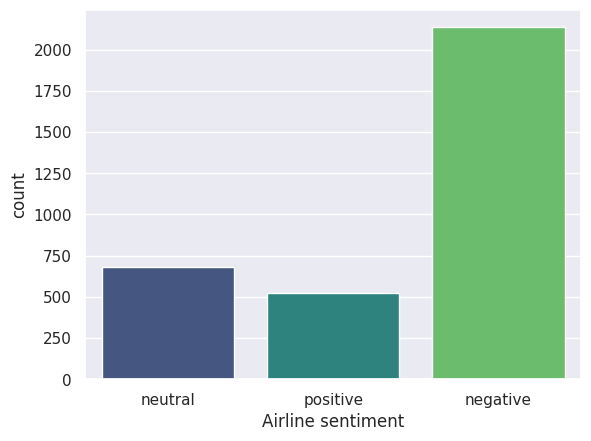

In [40]:
sns.countplot(df, x='airline_sentiment', palette="viridis")
plt.xlabel("Airline sentiment")
plt.ylabel("count")
plt.show()

# **Sentiment Prediction**
Excluding neutral cases and evaluating predictions on positive/negative classes.

In [41]:
df = df[df['airline_sentiment'] != 'neutral']

# Drop nulls and cast to string
df = df.dropna(subset=['text'])
df['text'] = df['text'].astype(str)
df['target'] = df['airline_sentiment'].map({'positive': 1, 'negative': 0})

print("Number of rows:", df.shape[0])
texts = df['text'].tolist()
predictions = classifier(texts)
predictions[:5]

Number of rows: 2659


[{'label': 'POSITIVE', 'score': 0.6070855855941772},
 {'label': 'NEGATIVE', 'score': 0.9973449110984802},
 {'label': 'NEGATIVE', 'score': 0.9995823502540588},
 {'label': 'NEGATIVE', 'score': 0.9854251742362976},
 {'label': 'POSITIVE', 'score': 0.9553211331367493}]

# **Performance Metrics Evaluation**
Calculating prediction accuracy.

In [42]:
probs = [pred['score'] if pred['label'].startswith('P') else 1 - pred['score'] for pred in predictions]
preds = np.array([1 if pred['label'].startswith('P') else 0 for pred in predictions])

print(f"Accuracy: {round(np.mean(df['target'] == preds) * 100, 2)} %")
cm = confusion_matrix(df['target'], preds, normalize='true')

Accuracy: 88.64 %


# **Confusion Matrix Visualization**
Plotting normalized performance matrix.

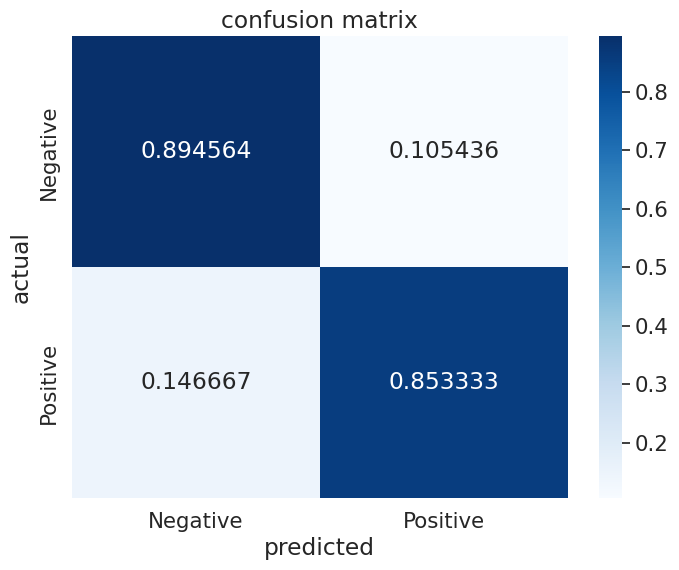

In [43]:
cm = confusion_matrix(df['target'], preds, normalize='true')

def plot_confusion_matrix(confusion_matrix, labels):
    plt.figure(figsize=(8,6))
    sns.set(font_scale=1.4)
    sns.heatmap(confusion_matrix, annot=True, fmt='g', cmap="Blues", xticklabels=labels, yticklabels=labels)
    plt.title("confusion matrix")
    plt.xlabel("predicted")
    plt.ylabel("actual")
    plt.show()

plot_confusion_matrix(cm, ["Negative", "Positive"])

### **Conclusion Summary**
* **Performance**: The pretrained DistilBERT pipeline achieved **88.64% accuracy** on the US Airline Sentiment dataset.
* **Limitation**: Testing revealed severe blind spots with context-shifting slang (*"the shit"*, *"bad ass"*) and random gibberish.
* **Takeaway**: Pretrained models are highly capable for standard text. However internet culture and words make domain specific fine tuning a prerequisite to handle informal social media nuances accurately.